# Assignment 6

## **Task 1**

## Importing the data

The import gives back 3 things I care about:
* `data.data` - every image flattened into one row of 4096 pixel values (64 x 64 = 4096). The pixel values are already scaled between 0.0 and 1.0. This is what I use as my features.
* `data.target` - the subject ID (0 - 39) for each image. This is my target.

I am also turning the data into a dataframe, since the import only gives back numpy arrays. I make one column per pixel (`pixel_0` to `pixel_4095`) and add the target as the last column. This is just so I can inspect the data easily, I don't use the dataframe for modeling.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces(shuffle=True, random_state=42)

## one column per pixel
pixel_cols = [f"pixel_{i}" for i in range(data.data.shape[1])]

df = pd.DataFrame(data.data, columns=pixel_cols)
df["target"] = data.target

print(df.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 4097)


In [2]:
df.head(20)

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_4087,pixel_4088,pixel_4089,pixel_4090,pixel_4091,pixel_4092,pixel_4093,pixel_4094,pixel_4095,target
0,0.198347,0.235537,0.351240,0.409091,0.421488,0.429752,0.500000,0.528926,0.524793,0.553719,...,0.508264,0.524793,0.504132,0.483471,0.471074,0.285124,0.061983,0.128099,0.090909,20
1,0.185950,0.128099,0.115702,0.132231,0.185950,0.268595,0.433884,0.541322,0.570248,0.586777,...,0.396694,0.409091,0.301653,0.421488,0.462810,0.247934,0.190083,0.210744,0.210744,28
2,0.508264,0.603306,0.619835,0.628099,0.657025,0.665289,0.690083,0.727273,0.743802,0.768595,...,0.301653,0.305785,0.314050,0.326446,0.338843,0.330579,0.334711,0.342975,0.342975,3
3,0.136364,0.140496,0.185950,0.280992,0.318182,0.363636,0.409091,0.417355,0.438017,0.454545,...,0.169421,0.206612,0.276859,0.355372,0.685950,0.661157,0.280992,0.371901,0.276859,21
4,0.652893,0.644628,0.652893,0.706612,0.714876,0.719008,0.743802,0.747934,0.747934,0.756198,...,0.074380,0.074380,0.082645,0.082645,0.111570,0.070248,0.086777,0.185950,0.231405,9
5,0.520661,0.533058,0.541322,0.578512,0.623967,0.640496,0.648760,0.640496,0.648760,0.644628,...,0.425620,0.450413,0.400826,0.388430,0.367769,0.309917,0.371901,0.367769,0.355372,8
6,0.136364,0.119835,0.132231,0.111570,0.119835,0.123967,0.123967,0.128099,0.132231,0.144628,...,0.508264,0.619835,0.685950,0.479339,0.388430,0.533058,0.640496,0.657025,0.640496,32
7,0.247934,0.347107,0.466942,0.508264,0.574380,0.615702,0.669421,0.694215,0.710744,0.723140,...,0.070248,0.082645,0.078512,0.074380,0.082645,0.074380,0.111570,0.123967,0.119835,9
8,0.334711,0.388430,0.491736,0.623967,0.735537,0.764463,0.756198,0.764463,0.780992,0.801653,...,0.057851,0.082645,0.086777,0.078512,0.111570,0.107438,0.144628,0.161157,0.185950,26
9,0.285124,0.285124,0.272727,0.214876,0.169421,0.165289,0.264463,0.446281,0.491736,0.541322,...,0.342975,0.326446,0.322314,0.301653,0.289256,0.305785,0.301653,0.309917,0.314050,12


## Data inspection
Here, I am printing the amount of samples, how many unique subjects there are, the dimensionality of the features and the amount of images per subject.

* The `value_counts()` call checks that every subject really has 10 images, which means the classes are perfectly balanced.

In [3]:
print("Samples:", len(df))
print("Unique subjects:", df["target"].nunique())
print("Feature dimensions:", df.shape[1] - 1)
print(df["target"].value_counts().sort_index().head())  # 10 images per subject

Samples: 400
Unique subjects: 40
Feature dimensions: 4096
target
0    10
1    10
2    10
3    10
4    10
Name: count, dtype: int64


## Assign data to seperate arrays

I am doing this because I don't want to be using a dataframe for the actual modeling.

In [4]:
X = data.data
y = data.target

## Plotting the subject images
Here, I am plotting a 4 x 5 grid of faces, one face per subject, with the subject ID as the title.

I wanted to make sure this works independant of whether you import the data using the `shuffle=True` call or not.
To do this, I just created an array with the hardcoded ID's I wanted to use (subjects 0 - 19).
Then, I found an image for each ID using `np.where` on the target array and took the first match.
The title is taken from `data.target[i]` (the real label of that image) so the label is guaranteed to match the face.

I use `data.images` here because it is already 64 x 64, and `cmap="gray"` so matplotlib shows them in grayscale instead of a color map.

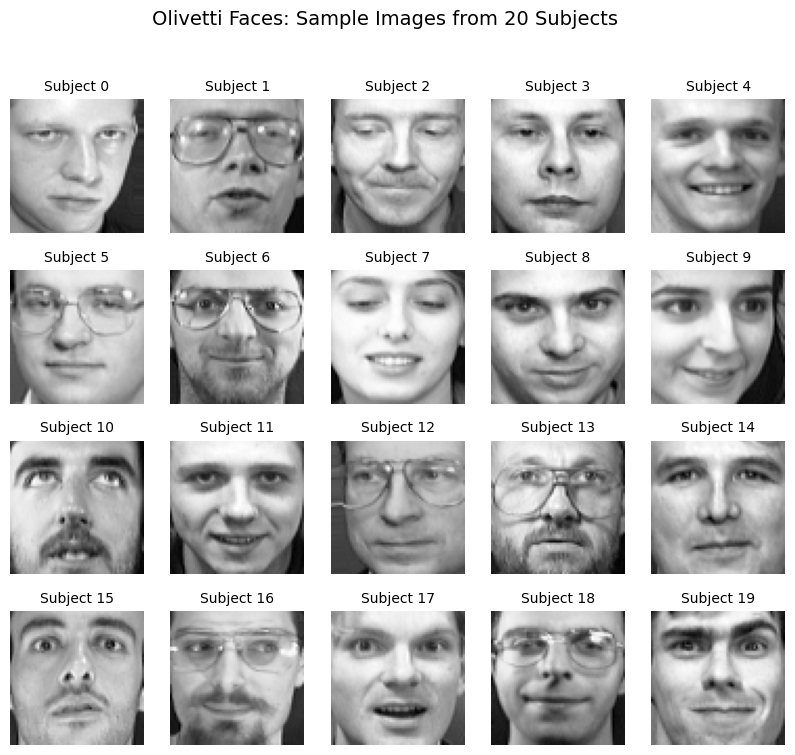

In [5]:
import numpy as np
import matplotlib.pyplot as plt

subject_ids = np.arange(20)
idx = [np.where(data.target == s)[0][0] for s in subject_ids]

fig, axes = plt.subplots(4, 5, figsize=(10, 8.5))

for ax, i in zip(axes.ravel(), idx):
    ax.imshow(data.images[i], cmap="gray")
    ax.set_title(f"Subject {data.target[i]}", fontsize=10)
    ax.axis("off")

fig.suptitle("Olivetti Faces: Sample Images from 20 Subjects", fontsize=14)
plt.show()

## **Task 2** Cumulative Explained Variance & Elbow Plot

Here, I am fitting a full PCA model to all 400 vectors

* `explained_variance_ratio_` gives the share of the total variance each component captures.
* `np.cumsum` adds those up so I can see how much variance the first k components keep together.
* For 90%, 95% and 99%, I find the smallest k where the cumulative variance reaches that threshold using `np.argmax(cumulative >= t) + 1`. The +1 is because indices start at 0.

**The plots:**
1. Left: the individual explained variance ratio (the elbow plot). I zoomed in on the first 60 components since that's where the drop off happens.
2. Right: the cumulative explained variance with dashed lines for the 3 thresholds.

Original feature dimensions: 4096
Principal components computed: 400
Variance explained by PC1: 0.2381
Variance explained by first 10 PCs: 0.6563

Components needed for 90% variance: 66  (1.61% of the original 4,096 dimensions)
Components needed for 95% variance: 123  (3.00% of the original 4,096 dimensions)
Components needed for 99% variance: 260  (6.35% of the original 4,096 dimensions)


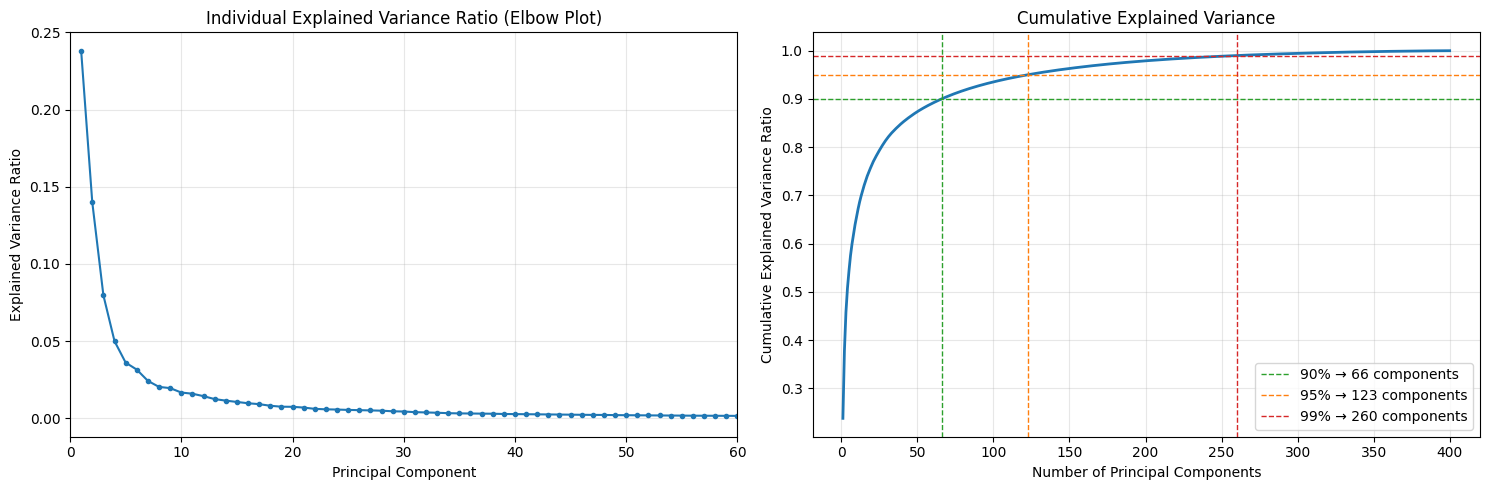

In [6]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print(f"Original feature dimensions: {X.shape[1]}")
print(f"Principal components computed: {len(explained)}")
print(f"Variance explained by PC1: {explained[0]:.4f}")
print(f"Variance explained by first 10 PCs: {cumulative[9]:.4f}\n")

## Smallest number of components that reaches each threshold
thresholds = [0.90, 0.95, 0.99]
n_components = {}
for t in thresholds:
    k = np.argmax(cumulative >= t) + 1
    n_components[t] = k
    print(f"Components needed for {int(t*100)}% variance: {k}  "
          f"({k / X.shape[1] * 100:.2f}% of the original 4,096 dimensions)")

n_components_95 = n_components[0.95]

## The actual plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
pcs = np.arange(1, len(explained) + 1)

## Left: individual explained variance ratio (elbow plot)
ax1.plot(pcs, explained, marker=".", color="tab:blue")
ax1.set_xlim(0, 60)
ax1.set_title("Individual Explained Variance Ratio (Elbow Plot)")
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance Ratio")
ax1.grid(True, alpha=0.3)

## Right: cumulative explained variance with the three thresholds
ax2.plot(pcs, cumulative, color="tab:blue", linewidth=2)
colors = {0.90: "tab:green", 0.95: "tab:orange", 0.99: "tab:red"}
for t, k in n_components.items():
    ax2.axhline(t, color=colors[t], linestyle="--", linewidth=1)
    ax2.axvline(k, color=colors[t], linestyle="--", linewidth=1,
                label=f"{int(t*100)}% → {k} components")
ax2.set_title("Cumulative Explained Variance")
ax2.set_xlabel("Number of Principal Components")
ax2.set_ylabel("Cumulative Explained Variance Ratio")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Above we see that 90% = 66 components, 95% = 123 components and 99% = 260 components. So only 123 out of 4096 dimensions (about 3%) are needed to keep 95% of the variance.
The elbow plot shows the first few components carry most of the information and then it drops off fast. The last 140 components only add the final 1% together, telling us they are basically just background noise.

## **Task 3**
## Image Compression and Reconstruction Analysis

Here, I am taking 5 faces and compressing them down to k components, then rebuilding them back into 64 x 64 images to see what gets lost.
I am using k = 10, 50, 100, 200, 300 so I can go from heavy compression (10 numbers instead of 4096, about 410x smaller) to very light compression.

* For each k, I fit a PCA with `n_components=k`.

I plot a grid with the originals in the first column and the rebuilt faces for each k in the other columns. Each row is the same face so it's easy to compare across k.

I also calculate the MSE (mean squared error)

k = 10: MSE = 0.00574
k = 50: MSE = 0.00238
k = 100: MSE = 0.00127
k = 200: MSE = 0.00042
k = 300: MSE = 0.00012


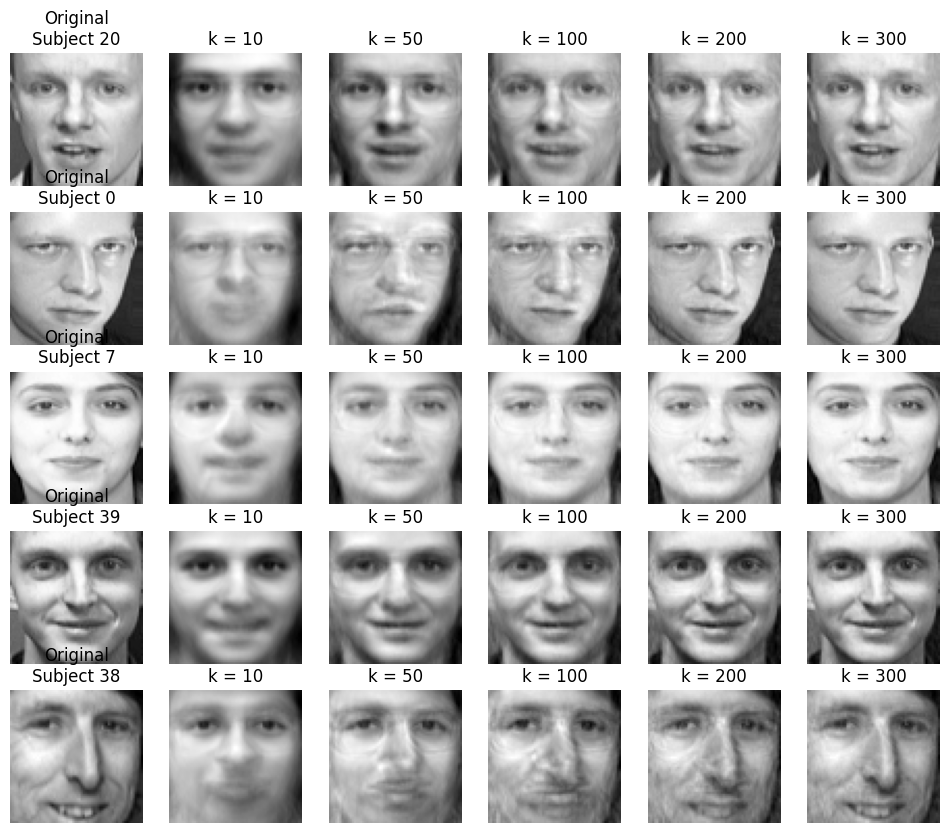

In [7]:
kValues = [10, 50, 100, 200, 300]
sampleIdx = [0, 10, 20, 30, 40]     ## the 5 faces I am comparing
mseList = []

fig, axes = plt.subplots(5, 6, figsize=(12, 10))

for row, i in enumerate(sampleIdx):
    axes[row, 0].imshow(X[i].reshape(64, 64), cmap="gray")
    axes[row, 0].set_title(f"Original\nSubject {y[i]}")
    axes[row, 0].axis("off")

for col, k in enumerate(kValues, start=1):
    pca = PCA(n_components=k)
    Xreduced = pca.fit_transform(X)
    Xrebuilt = pca.inverse_transform(Xreduced)

    mse = np.mean((X[sampleIdx] - Xrebuilt[sampleIdx]) ** 2)
    mseList.append(mse)
    print(f"k = {k}: MSE = {mse:.5f}")

    for row, i in enumerate(sampleIdx):
        axes[row, col].imshow(Xrebuilt[i].reshape(64, 64), cmap="gray")
        axes[row, col].set_title(f"k = {k}")
        axes[row, col].axis("off")

plt.show()

## Plotting the MSE
Here, I am plotting the MSE for each k to see how the reconstruction error changes as I keep more components.


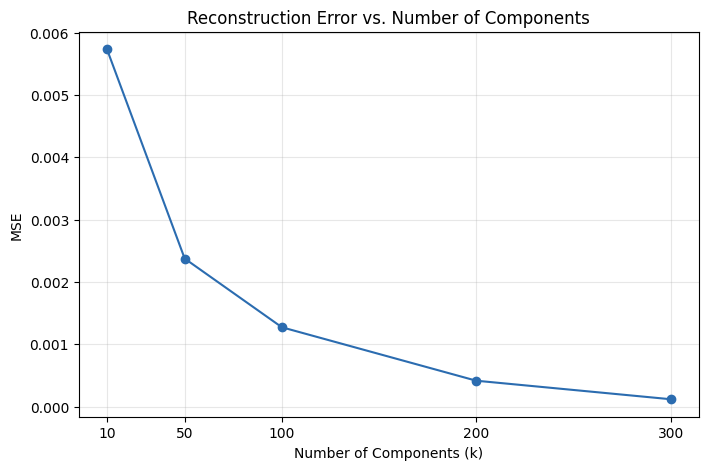

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kValues, mseList, marker="o", color="#2b6cb0")
ax.set_xticks(kValues)
ax.set_xlabel("Number of Components (k)")
ax.set_ylabel("MSE")
ax.set_title("Reconstruction Error vs. Number of Components")
ax.grid(True, alpha=0.3)
plt.show()

## **Task 4**
## Visualization of "Eigenfaces"

Here, I am taking the principal components from the full PCA model I fit in Task 2 (`pca_full`) and turning them back into pictures.

Each principal component is a vector of 4096 values, one for every pixel, so I can reshape it back into a 64 x 64 grid and plot it like a face.

I am plotting the first 15 components in a 3 x 5 grid. The values in a component can be positive or negative, so `imshow` just maps the lowest values to dark and the highest to bright.

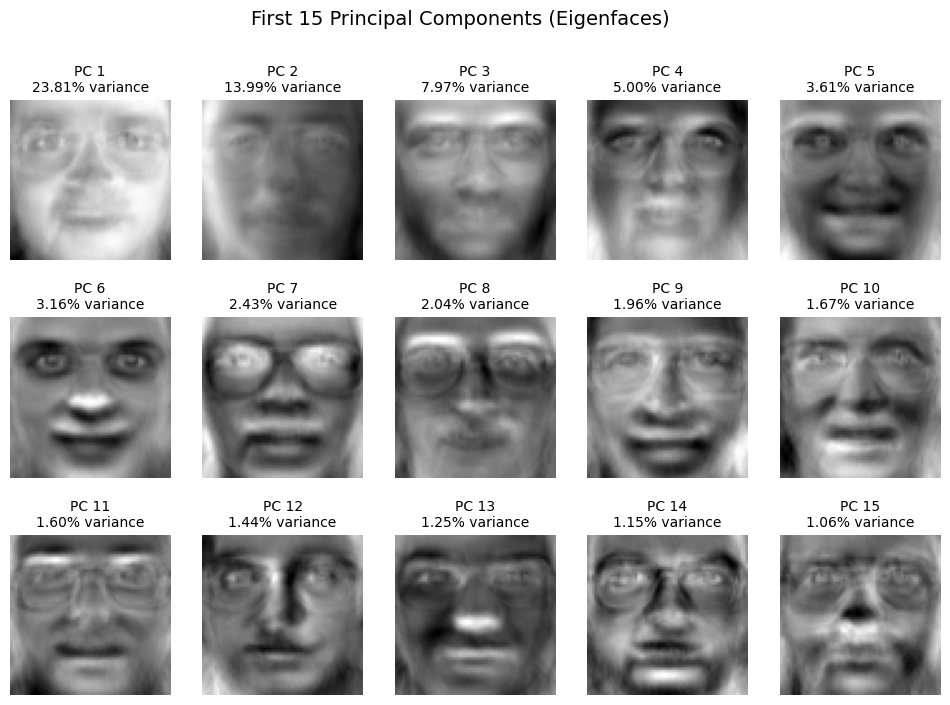

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(12, 8))

## ravel flattens a grid of subplot axes into a 1D list.
for i, ax in enumerate(axes.ravel()):
    eigenface = pca_full.components_[i].reshape(64, 64)   ## 4096 values -> 64 x 64 image
    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"PC {i + 1}\n{explained[i] * 100:.2f}% variance", fontsize=10)
    ax.axis("off")

fig.suptitle("First 15 Principal Components (Eigenfaces)", fontsize=14)
plt.show()

## **Task 5** Classification Baseline - Raw vs. PCA-Reduced Features (Linear Model)

## Splitting the data
Here, I am splitting the data 80-20 into training and test sets.
I use `stratify=y` so that the train and test sets have the same proportion of every subject.

In [10]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", Xtrain.shape)
print("Test: ", Xtest.shape)
print("Images per subject in test set:", np.bincount(yTest))

Train: (320, 4096)
Test:  (80, 4096)
Images per subject in test set: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2]


## Defining the Logistic Regression pipelines
Here, I am training `LogisticRegression` two ways and also time both

For the PCA one, I set `n_components=0.95`.

Since the PCA is only fit on 320 training images (not all 400), the number of components for 95% can be a little different from the 123 I got in Task 2, so I print it out.

I time the `fit` call with `time.time()` before and after. For the PCA pipeline the time includes fitting the PCA too, since that's part of the training cost.
I set `max_iter=1000` so Logistic Regression has enough iterations to converge

I also make a `results` dictionary to save each model's accuracy and training time, so I can use them all together in Task 8.

In [11]:
import time
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

results = {}    ## holds the accuracy and training time of every model for task 8

## 1. Logistic Regression on raw 4096 pixel features
lrRaw = LogisticRegression(max_iter=1000, random_state=42)

start = time.time()
lrRaw.fit(Xtrain, yTrain)
lrRawTime = time.time() - start

lrRawPred = lrRaw.predict(Xtest)
lrRawAcc = accuracy_score(yTest, lrRawPred)
results["Logistic Reg.\n(Raw 4096 dim)"] = [lrRawAcc, lrRawTime]

## 2. Logistic Regression on PCA features (95% variance, PCA fit only on the training set)
lrPcaPipe = Pipeline([
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])

start = time.time()
lrPcaPipe.fit(Xtrain, yTrain)
lrPcaTime = time.time() - start

lrPcaPred = lrPcaPipe.predict(Xtest)
lrPcaAcc = accuracy_score(yTest, lrPcaPred)

nPcaTrain = lrPcaPipe.named_steps['pca'].n_components_     ## how many components PCA kept for 95%
results[f"Logistic Reg.\n(PCA {nPcaTrain} dim)"] = [lrPcaAcc, lrPcaTime]

print("Components kept for 95% (fit on training set):", nPcaTrain)
print(f"Logistic Regression (raw): accuracy = {lrRawAcc:.4f}, training time = {lrRawTime:.2f}s")
print(f"Logistic Regression (PCA): accuracy = {lrPcaAcc:.4f}, training time = {lrPcaTime:.2f}s")

Components kept for 95% (fit on training set): 111
Logistic Regression (raw): accuracy = 0.9750, training time = 25.53s
Logistic Regression (PCA): accuracy = 0.9750, training time = 0.53s


## Plotting accuracy vs. training time
Here, I am making a dual-axis bar plot to compare the two models.
Accuracy and training time have totally different scales (0 - 1 vs. seconds), so I use `ax1.twinx()` to make a second y-axis that shares the same x-axis. Accuracy goes on the left axis (blue) and training time on the right axis (orange).

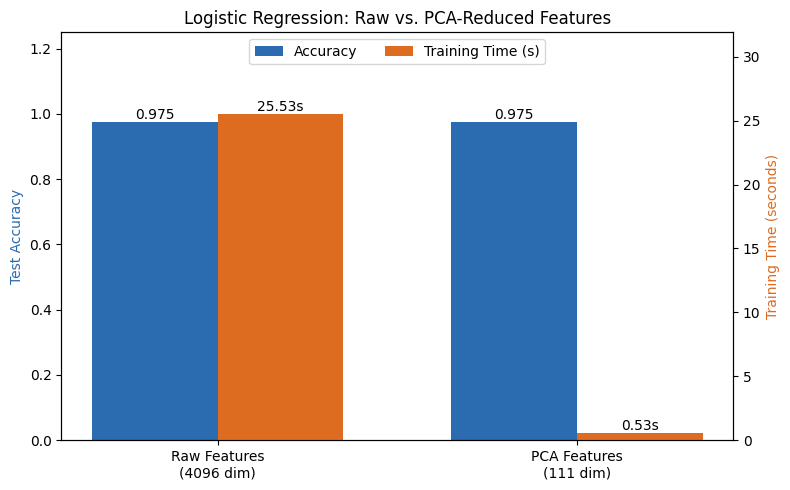

In [12]:
labels = ["Raw Features\n(4096 dim)", f"PCA Features\n({nPcaTrain} dim)"]
accs = [lrRawAcc, lrPcaAcc]
times = [lrRawTime, lrPcaTime]

x = np.arange(len(labels))
width = 0.35

fig, ax1 = plt.subplots(figsize=(8, 5))

## accuracy on the left axis
bars1 = ax1.bar(x - width/2, accs, width, label="Accuracy", color="#2b6cb0")
ax1.bar_label(bars1, fmt="%.3f")
ax1.set_ylabel("Test Accuracy", color="#2b6cb0")
ax1.set_ylim(0, 1.25)

## training time on the right axis
ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, times, width, label="Training Time (s)", color="#dd6b20")
ax2.bar_label(bars2, fmt="%.2fs")
ax2.set_ylabel("Training Time (seconds)", color="#dd6b20")
ax2.set_ylim(0, max(times) * 1.25)

ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_title("Logistic Regression: Raw vs. PCA-Reduced Features")
ax1.legend(handles=[bars1, bars2], loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

## **Task 6**
## Non-Linear Classification (Kernel SVM)

Here, I am training an `SVC` with an RBF kernel on the same PCA-reduced features (95% variance).
I also used both a  classification report and confusion matrix just to see how both would help.
The classification report is less useful as the classes are perfectly balanced. Every subject has exactly 2 test images so macro and weighted averages come out the same, basically just confirming the accuracy ranking rather than saying anything new.

In [13]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

svcPipe = Pipeline([
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('svc', SVC(kernel='rbf', random_state=42))
])

start = time.time()
svcPipe.fit(Xtrain, yTrain)
svcTime = time.time() - start

svcPred = svcPipe.predict(Xtest)
svcAcc = accuracy_score(yTest, svcPred)
results[f"SVC (RBF)\n(PCA {nPcaTrain} dim)"] = [svcAcc, svcTime]

print(f"SVC (RBF, PCA): accuracy = {svcAcc:.4f}, training time = {svcTime:.2f}s")
print(f"Logistic Regression (PCA): accuracy = {lrPcaAcc:.4f}, training time = {lrPcaTime:.2f}s")
print("Test images where the two models disagree:", np.sum(svcPred != lrPcaPred))

SVC (RBF, PCA): accuracy = 0.9500, training time = 0.18s
Logistic Regression (PCA): accuracy = 0.9750, training time = 0.53s
Test images where the two models disagree: 2


## Confusion matrices: Logistic Regression vs. SVM
Here, I am plotting the confusion matrices of the PCA Logistic Regression and the RBF SVM side by side.
There are 40 subjects, so each matrix is 40 x 40.
I turned off the numbers inside the squares (`include_values=False`) because with 1600 squares they would just be unreadable. The color shows the count instead.

After, I put both classification reports into one table (like I did in the heart disease homework) so I can compare the overall precision, recall and f1 of each model.

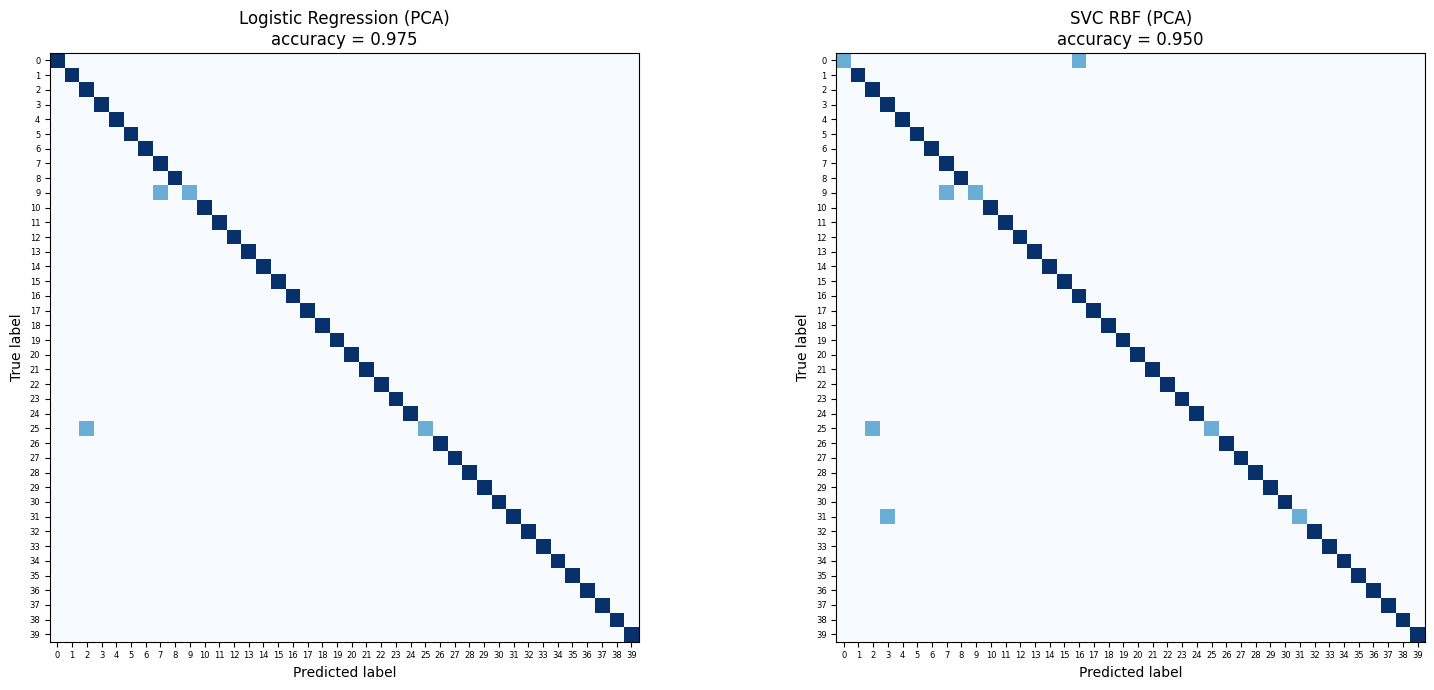

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

models = {"Logistic Regression (PCA)": lrPcaPred, "SVC RBF (PCA)": svcPred}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, preds) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        yTest, preds,
        include_values=False,      ## 40 x 40 is too many numbers to read
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f"{name}\naccuracy = {accuracy_score(yTest, preds):.3f}")
    ax.tick_params(labelsize=6)

plt.tight_layout()
plt.show()

In [15]:
## overall precision / recall / f1 for both models next to each other
reports = {}
for name, preds in models.items():
    report = pd.DataFrame(classification_report(yTest, preds, output_dict=True, zero_division=0)).T
    reports[name] = report.loc[["accuracy", "macro avg", "weighted avg"]]

pd.concat(reports, axis=1).round(3)

Logistic Regression (PCA)                         SVC RBF (PCA)  \
                             precision recall f1-score support     precision   
accuracy                         0.975  0.975    0.975   0.975         0.950   
macro avg                        0.983  0.975    0.973  80.000         0.967   
weighted avg                     0.983  0.975    0.973  80.000         0.967   

                                      
             recall f1-score support  
accuracy       0.95    0.950    0.95  
macro avg      0.95    0.947   80.00  
weighted avg   0.95    0.947   80.00

## **Task 7**
## Ensemble Classification on PCA Features

Here, I am making a soft voting `VotingClassifier` that combines 3 different models, all trained on the PCA-reduced features

In [16]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

## defining the pipeline
votingClfPipe = Pipeline([
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('VotingClf', VotingClassifier(
            estimators=[
                ('polySVM', SVC(kernel='poly', degree=2, probability=True, random_state=42)),
                ('rbfSVM', SVC(kernel='rbf', probability=True, random_state=42)),
                ('forest', RandomForestClassifier(n_estimators=100, random_state=42))
            ],
            voting='soft'
        )
    )
])

start = time.time()
votingClfPipe.fit(Xtrain, yTrain)
votingTime = time.time() - start

votingPred = votingClfPipe.predict(Xtest)
votingAcc = accuracy_score(yTest, votingPred)
results[f"Soft Voting\n(PCA {nPcaTrain} dim)"] = [votingAcc, votingTime]

print(f"Soft Voting Ensemble (PCA): accuracy = {votingAcc:.4f}, training time = {votingTime:.2f}s")

Soft Voting Ensemble (PCA): accuracy = 0.9750, training time = 1.02s


## Testing each individual model inside the ensemble
Here, I am checking how good each of the 3 models is on its own compared to the ensemble.
I have to push the Xtest data through the PCA step of the pipeline first, because the models inside the voting classifier were trained on the PCA features and not the raw pixels.
I also had to get the classifier from the pipeline using `named_steps` before doing any testing.

In [17]:
## getting the step of the pipeline that contains the classifier
vc = votingClfPipe.named_steps['VotingClf']

## I have to push the Xtest data through the pca step first so it is in the same space the models were trained on
XtestPca = votingClfPipe.named_steps['pca'].transform(Xtest)

## tell me the performance of each individual model
for name, clf in vc.named_estimators_.items():
    print(name, "=", round(clf.score(XtestPca, yTest), 4))
print("Soft Voting =", round(votingAcc, 4))
print()
print("Logistic Regression (PCA) =", round(lrPcaAcc, 4))
print("SVC RBF (PCA) =", round(svcAcc, 4))

polySVM = 0.7875
rbfSVM = 0.95
forest = 0.9625
Soft Voting = 0.975

Logistic Regression (PCA) = 0.975
SVC RBF (PCA) = 0.95


## **Task 8**
## Comprehensive Comparative Evaluation

Here, I am putting all 4 model setups into one summary plot:
1. Logistic Regression (Raw Features)
2. Logistic Regression (PCA-Reduced)
3. Support Vector Classifier with RBF Kernel (PCA-Reduced)
4. Soft Voting Ensemble (PCA-Reduced)

I use the `results` dictionary I filled in during Tasks 5 - 7, so every number in the plot is the real accuracy and training time from this run (nothing is typed in by hand).

First I print the results as a table using a dataframe. Then I make the same kind of dual-axis bar plot as Task 5: accuracy on the primary (left) y-axis and training time in seconds on the secondary (right) y-axis using `twinx()`. This lets me see the trade-off between how accurate each model is and how expensive it is to train in one picture.

In [18]:
summary = pd.DataFrame(results, index=["Accuracy", "Training Time (s)"]).T
summary.index = [name.replace("\n", " ") for name in summary.index]
summary.round(4)

,Accuracy,Training Time (s)
Logistic Reg. (Raw 4096 dim),0.975,25.5332
Logistic Reg. (PCA 111 dim),0.975,0.5305
SVC (RBF) (PCA 111 dim),0.950,0.1810
Soft Voting (PCA 111 dim),0.975,1.0238


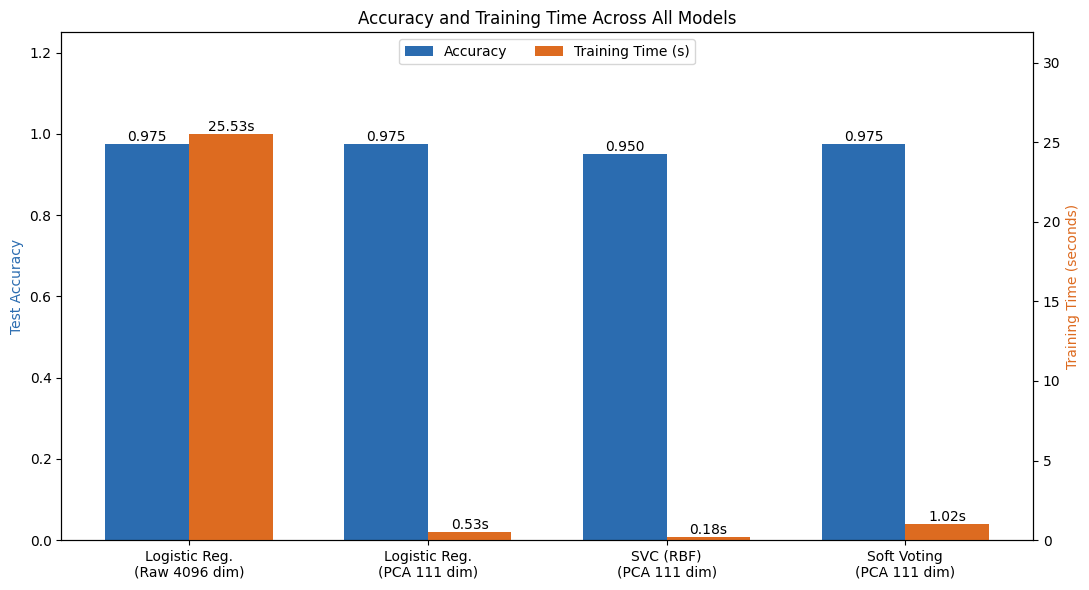

In [19]:
modelNames = list(results.keys())
accs = [v[0] for v in results.values()]
times = [v[1] for v in results.values()]

x = np.arange(len(modelNames))
width = 0.35

fig, ax1 = plt.subplots(figsize=(11, 6))

## accuracy on the primary axis
bars1 = ax1.bar(x - width/2, accs, width, label="Accuracy", color="#2b6cb0")
ax1.bar_label(bars1, fmt="%.3f")
ax1.set_ylabel("Test Accuracy", color="#2b6cb0")
ax1.set_ylim(0, 1.25)

## training time on the secondary axis
ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, times, width, label="Training Time (s)", color="#dd6b20")
ax2.bar_label(bars2, fmt="%.2fs")
ax2.set_ylabel("Training Time (seconds)", color="#dd6b20")
ax2.set_ylim(0, max(times) * 1.25)

ax1.set_xticks(x)
ax1.set_xticklabels(modelNames)
ax1.set_title("Accuracy and Training Time Across All Models")
ax1.legend(handles=[bars1, bars2], loc="upper center", ncol=2)
plt.tight_layout()
plt.show()